#### [CLS] vs. Masked Mean Pooling + Logistic Regression

### SUMMARY
The Goal: Extract a single 768-dimensional vector representing the entire tweet and train a simple LogisticRegression on top.

[CLS] Token: Taking the embedding of the first token [CLS] (at index 0).

Mean Pooling: Taking the average of all token embeddings in the tweet, weighted by the attention mask so padding tokens (<PAD>) don't corrupt the average.

Logistic Regression with Thresholding: Since sarcasm is heavily imbalanced, you predict probabilities on val and pick the optimal threshold that maximizes the F1-score of the sarcastic class.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Préprocesseur officiel AraBERT et HuggingFace Transformers
from arabert.preprocess import ArabertPreprocessor
from transformers import AutoTokenizer, AutoModel

# Fixer la graine pour la reproductibilité
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device utilisé : {DEVICE}")


c:\ghoufrane\Master\M2\llms\Hanwritten-code-For-LLM-FineTuning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device utilisé : cuda


In [3]:
# Loading raw data
train_df = pd.read_csv(r"..\\Notebooks\\data\\aravec_splits\\aravec_train.csv")
val_df = pd.read_csv(r"..\\Notebooks\\data\\aravec_splits\\aravec_val.csv")
test_df = pd.read_csv(r"..\\Notebooks\\data\\aravec_splits\\aravec_test.csv")

print(f"Raw splits loaded: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

Raw splits loaded: Train=11293, Val=1255, Test=3000


In [4]:
# Labels sous forme d'entiers (0 = non sarcastique, 1 = sarcastique)
y_train = train_df["sarcasm"].astype(int).values
y_val = val_df["sarcasm"].astype(int).values
y_test = test_df["sarcasm"].astype(int).values

In [5]:
# 2. Initialisation du préprocesseur officiel AraBERT Twitter
MODEL_NAME = "aubmindlab/bert-base-arabertv02-twitter"
arabert_prep = ArabertPreprocessor(model_name=MODEL_NAME)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [6]:
print("Application du prétraitement AraBERT...")
train_texts = [arabert_prep.preprocess(str(t)) for t in train_df["tweet"]]
val_texts = [arabert_prep.preprocess(str(t)) for t in val_df["tweet"]]
test_texts = [arabert_prep.preprocess(str(t)) for t in test_df["tweet"]]
print("\n--- Exemple avant / après prétraitement AraBERT ---")
print("Brut    :", train_df["tweet"].iloc[0])
print("Prétraité :", train_texts[0])


Application du prétraitement AraBERT...

--- Exemple avant / après prétraitement AraBERT ---
Brut    : "#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
Prétraité : " # لافروف : # موسكو تأمل بإجراء حوار بناء بشأن الأزمة في # سورية خلال لقائي مع وزيري خارجية # إيران و # تركيا غدا [رابط] "


### D1 : Extraction des représentations ([CLS] et Mean Pooling)

Explication : L'encodeur AraBERT est gelé (param.requires_grad = False et torch.no_grad()).
 On extrait pour Train, Val et Test :

Le vecteur du token [CLS] (token à l'indice 0).

La moyenne pondérée par le masque d'attention (Mean Pooling) pour exclure les tokens de padding.


In [7]:
import sys
print(sys.executable)


c:\ghoufrane\Master\M2\llms\Hanwritten-code-For-LLM-FineTuning\.venv\Scripts\python.exe


In [8]:
encoder = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
encoder.eval()
for param in encoder.parameters():
    param.requires_grad = False

MAX_LEN = 128
BATCH_SIZE = 64

def extract_plm_features(texts, model, tokenizer, max_len=128, batch_size=64):
    cls_features = []
    mean_features = []
    
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i : i + batch_size]
            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_len,
                return_tensors="pt"
            ).to(DEVICE)
            
            outputs = model(**encoded)
            last_hidden = outputs.last_hidden_state       # (B, L, 768)
            attention_mask = encoded["attention_mask"]    # (B, L)
            
            # 1. Vecteur [CLS]
            cls_rep = last_hidden[:, 0, :]
            cls_features.append(cls_rep.cpu().numpy())
            
            # 2. Moyenne pondérée par le masque d'attention (ignorer le PAD)
            mask_expanded = attention_mask.unsqueeze(-1).expand_as(last_hidden).float()
            sum_embeddings = torch.sum(last_hidden * mask_expanded, dim=1)
            sum_mask = torch.clamp(mask_expanded.sum(dim=1), min=1e-9)
            mean_rep = sum_embeddings / sum_mask
            mean_features.append(mean_rep.cpu().numpy())
            
    return np.vstack(cls_features), np.vstack(mean_features)

print("Extraction pour Train...")
X_train_cls, X_train_mean = extract_plm_features(train_texts, encoder, tokenizer, MAX_LEN, BATCH_SIZE)

print("Extraction pour Val...")
X_val_cls, X_val_mean = extract_plm_features(val_texts, encoder, tokenizer, MAX_LEN, BATCH_SIZE)

print("Extraction pour Test...")
X_test_cls, X_test_mean = extract_plm_features(test_texts, encoder, tokenizer, MAX_LEN, BATCH_SIZE)

print("Forme des features :", X_train_cls.shape)


Some weights of BertModel were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Extraction pour Train...
Extraction pour Val...
Extraction pour Test...
Forme des features : (11293, 768)


### 1 : Régression Logistique, Seuil optimal sur Val, et Test final

In [9]:
def find_best_threshold(y_true, y_probs):
    thresholds = np.linspace(0.1, 0.9, 81)
    best_thresh = 0.5
    best_f1 = 0.0
    for t in thresholds:
        preds = (y_probs >= t).astype(int)
        score = f1_score(y_true, preds, pos_label=1, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_thresh = t
    return best_thresh, best_f1

def evaluate_d1(name, X_tr, y_tr, X_va, y_va, X_te, y_te):
    clf = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    clf.fit(X_tr, y_tr)
    
    # 1. Sélection du seuil sur Val
    val_probs = clf.predict_proba(X_va)[:, 1]
    best_thresh, best_val_f1 = find_best_threshold(y_va, val_probs)
    
    # 2. Évaluation sur Test au seuil choisi sur Val
    test_probs = clf.predict_proba(X_te)[:, 1]
    test_preds = (test_probs >= best_thresh).astype(int)
    
    test_f1 = f1_score(y_te, test_preds, pos_label=1, zero_division=0)
    p, r, _, _ = precision_recall_fscore_support(y_te, test_preds, pos_label=1, average="binary")
    macro_f1 = f1_score(y_te, test_preds, average="macro")
    
    print(f"==================================================")
    print(f"Modèle D1 : {name}")
    print(f"==================================================")
    print(f"• Seuil optimal sélectionné sur Val : {best_thresh:.2f} (F1 Val = {best_val_f1:.4f})")
    print(f"• RÉSULTATS SUR TEST (au seuil {best_thresh:.2f}) :")
    print(f"   - F1 Sarcasme (métrique officielle) : {test_f1:.4f}")
    print(f"   - Précision Sarcasme                : {p:.4f}")
    print(f"   - Rappel Sarcasme                   : {r:.4f}")
    print(f"   - Macro F1                          : {macro_f1:.4f}")
    print("\nRapport complet sur Test :")
    print(classification_report(y_te, test_preds, target_names=["Non-sarcastique", "Sarcastique"], digits=4))
    
    return clf, best_thresh, test_f1

print("--- Évaluation D1 sur le TEST ---")
clf_cls, th_cls, test_f1_cls = evaluate_d1("[CLS] + Régression Logistique", X_train_cls, y_train, X_val_cls, y_val, X_test_cls, y_test)
clf_mean, th_mean, test_f1_mean = evaluate_d1("Moyenne Pondérée + Régression Logistique", X_train_mean, y_train, X_val_mean, y_val, X_test_mean, y_test)


--- Évaluation D1 sur le TEST ---
Modèle D1 : [CLS] + Régression Logistique
• Seuil optimal sélectionné sur Val : 0.59 (F1 Val = 0.6119)
• RÉSULTATS SUR TEST (au seuil 0.59) :
   - F1 Sarcasme (métrique officielle) : 0.5965
   - Précision Sarcasme                : 0.5229
   - Rappel Sarcasme                   : 0.6943
   - Macro F1                          : 0.7040

Rapport complet sur Test :
                 precision    recall  f1-score   support

Non-sarcastique     0.8686    0.7614    0.8114      2179
    Sarcastique     0.5229    0.6943    0.5965       821

       accuracy                         0.7430      3000
      macro avg     0.6958    0.7278    0.7040      3000
   weighted avg     0.7740    0.7430    0.7526      3000

Modèle D1 : Moyenne Pondérée + Régression Logistique
• Seuil optimal sélectionné sur Val : 0.72 (F1 Val = 0.6161)
• RÉSULTATS SUR TEST (au seuil 0.72) :
   - F1 Sarcasme (métrique officielle) : 0.5928
   - Précision Sarcasme                : 0.5609
   - Rappe

### D2 : Architecture BiLSTM + Pooling Attentionnel de C2

In [11]:
class BiLSTMAttentionClassifier(nn.Module):
    def __init__(self, plm_hidden_size=768, lstm_hidden_size=128, attn_dim=64, num_classes=2, dropout=0.3):
        super().__init__()
        # 1. BiLSTM
        self.bilstm = nn.LSTM(
            input_size=plm_hidden_size,
            hidden_size=lstm_hidden_size,
            batch_first=True,
            bidirectional=True
        )
        
        # 2. Attention de C2 : alpha_i = softmax(v^T tanh(W h_i))
        bi_dim = lstm_hidden_size * 2
        self.W = nn.Linear(bi_dim, attn_dim)
        self.v = nn.Linear(attn_dim, 1, bias=False)
        
        # 3. Classifieur
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(bi_dim, num_classes)
        
    def forward(self, hidden_states, attention_mask):
        # BiLSTM -> (B, L, 2 * H)
        lstm_out, _ = self.bilstm(hidden_states)
        
        # Attention additive (C2)
        u = torch.tanh(self.W(lstm_out))        # (B, L, attn_dim)
        scores = self.v(u).squeeze(-1)           # (B, L)
        
        # Masquer les positions de padding
        scores = scores.masked_fill(attention_mask == 0, -1e9)
        attn_weights = F.softmax(scores, dim=-1) # (B, L)
        
        # Vecteur de contexte c = sum(alpha_i * h_i)
        context = torch.bmm(attn_weights.unsqueeze(1), lstm_out).squeeze(1) # (B, 2 * H)
        logits = self.classifier(self.dropout(context))
        
        return logits, attn_weights

class TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len
        
    def __len__(self):
        return len(self.texts)
        
    def __getitem__(self, idx):
        encoded = self.tokenizer(
            str(self.texts[idx]),
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = TweetDataset(train_texts, y_train, tokenizer, MAX_LEN)
val_dataset = TweetDataset(val_texts, y_val, tokenizer, MAX_LEN)
test_dataset = TweetDataset(test_texts, y_test, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


### D2 : Entraînement de la tête (PLM gelé) avec validation

In [12]:
# Pondération de la perte pour gérer le déséquilibre
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
weights = torch.tensor([1.0, num_neg / num_pos], dtype=torch.float).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=weights)

d2_head = BiLSTMAttentionClassifier().to(DEVICE)
optimizer = torch.optim.AdamW(d2_head.parameters(), lr=1e-3, weight_decay=1e-2)

EPOCHS = 6
best_val_f1 = 0.0
best_thresh_d2 = 0.5
best_weights = None

for epoch in range(EPOCHS):
    d2_head.train()
    total_loss = 0.0
    
    for batch in train_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        mask = batch["attention_mask"].to(DEVICE)
        labels = batch["label"].to(DEVICE)
        
        # Passage dans AraBERT gelé
        with torch.no_grad():
            outputs = encoder(input_ids=input_ids, attention_mask=mask)
            hidden_states = outputs.last_hidden_state
            
        optimizer.zero_grad()
        logits, _ = d2_head(hidden_states, mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        
    # Évaluation sur Val
    d2_head.eval()
    val_probs = []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            outputs = encoder(input_ids=input_ids, attention_mask=mask)
            logits, _ = d2_head(outputs.last_hidden_state, mask)
            probs = F.softmax(logits, dim=-1)[:, 1]
            val_probs.extend(probs.cpu().numpy())
            
    val_probs = np.array(val_probs)
    thresh, epoch_f1 = find_best_threshold(y_val, val_probs)
    print(f"Époque {epoch+1}/{EPOCHS} - Perte: {total_loss/len(train_loader):.4f} | Val F1 (seuil {thresh:.2f}): {epoch_f1:.4f}")
    
    if epoch_f1 > best_val_f1:
        best_val_f1 = epoch_f1
        best_thresh_d2 = thresh
        best_weights = d2_head.state_dict().copy()

# Restauration du meilleur modèle
d2_head.load_state_dict(best_weights)
print(f"\nMeilleur F1 Val : {best_val_f1:.4f} (Seuil sélectionné : {best_thresh_d2:.2f})")


Époque 1/6 - Perte: 0.4391 | Val F1 (seuil 0.70): 0.6785
Époque 2/6 - Perte: 0.3589 | Val F1 (seuil 0.58): 0.6535
Époque 3/6 - Perte: 0.2937 | Val F1 (seuil 0.78): 0.6364
Époque 4/6 - Perte: 0.2187 | Val F1 (seuil 0.50): 0.6512
Époque 5/6 - Perte: 0.1685 | Val F1 (seuil 0.64): 0.6498
Époque 6/6 - Perte: 0.1341 | Val F1 (seuil 0.27): 0.6463

Meilleur F1 Val : 0.6785 (Seuil sélectionné : 0.70)


### D2 : Évaluation sur les données de TEST

In [13]:
# Évaluation sur Test avec les états extraits et le seuil optimisé sur Val
d2_head.eval()
test_probs = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        mask = batch["attention_mask"].to(DEVICE)
        outputs = encoder(input_ids=input_ids, attention_mask=mask)
        logits, _ = d2_head(outputs.last_hidden_state, mask)
        probs = F.softmax(logits, dim=-1)[:, 1]
        test_probs.extend(probs.cpu().numpy())

test_probs = np.array(test_probs)
test_preds = (test_probs >= best_thresh_d2).astype(int)

test_f1 = f1_score(y_test, test_preds, pos_label=1)
p, r, _, _ = precision_recall_fscore_support(y_test, test_preds, pos_label=1, average="binary")
macro_f1 = f1_score(y_test, test_preds, average="macro")

print("==================================================")
print("RÉSULTATS FINAUX D2 (BiLSTM + Attention C2) SUR TEST")
print("==================================================")
print(f"• Seuil appliqué (calibré sur Val)  : {best_thresh_d2:.2f}")
print(f"• F1 Sarcasme (métrique officielle) : {test_f1:.4f}")
print(f"• Précision Sarcasme                : {p:.4f}")
print(f"• Rappel Sarcasme                   : {r:.4f}")
print(f"• Macro F1                          : {macro_f1:.4f}\n")
print(classification_report(y_test, test_preds, target_names=["Non-sarcastique", "Sarcastique"], digits=4))


RÉSULTATS FINAUX D2 (BiLSTM + Attention C2) SUR TEST
• Seuil appliqué (calibré sur Val)  : 0.70
• F1 Sarcasme (métrique officielle) : 0.5379
• Précision Sarcasme                : 0.6200
• Rappel Sarcasme                   : 0.4750
• Macro F1                          : 0.6953

                 precision    recall  f1-score   support

Non-sarcastique     0.8182    0.8903    0.8527      2179
    Sarcastique     0.6200    0.4750    0.5379       821

       accuracy                         0.7767      3000
      macro avg     0.7191    0.6827    0.6953      3000
   weighted avg     0.7640    0.7767    0.7666      3000



### Visualisation de l'attention sur 5 tweets sarcastiques du TEST

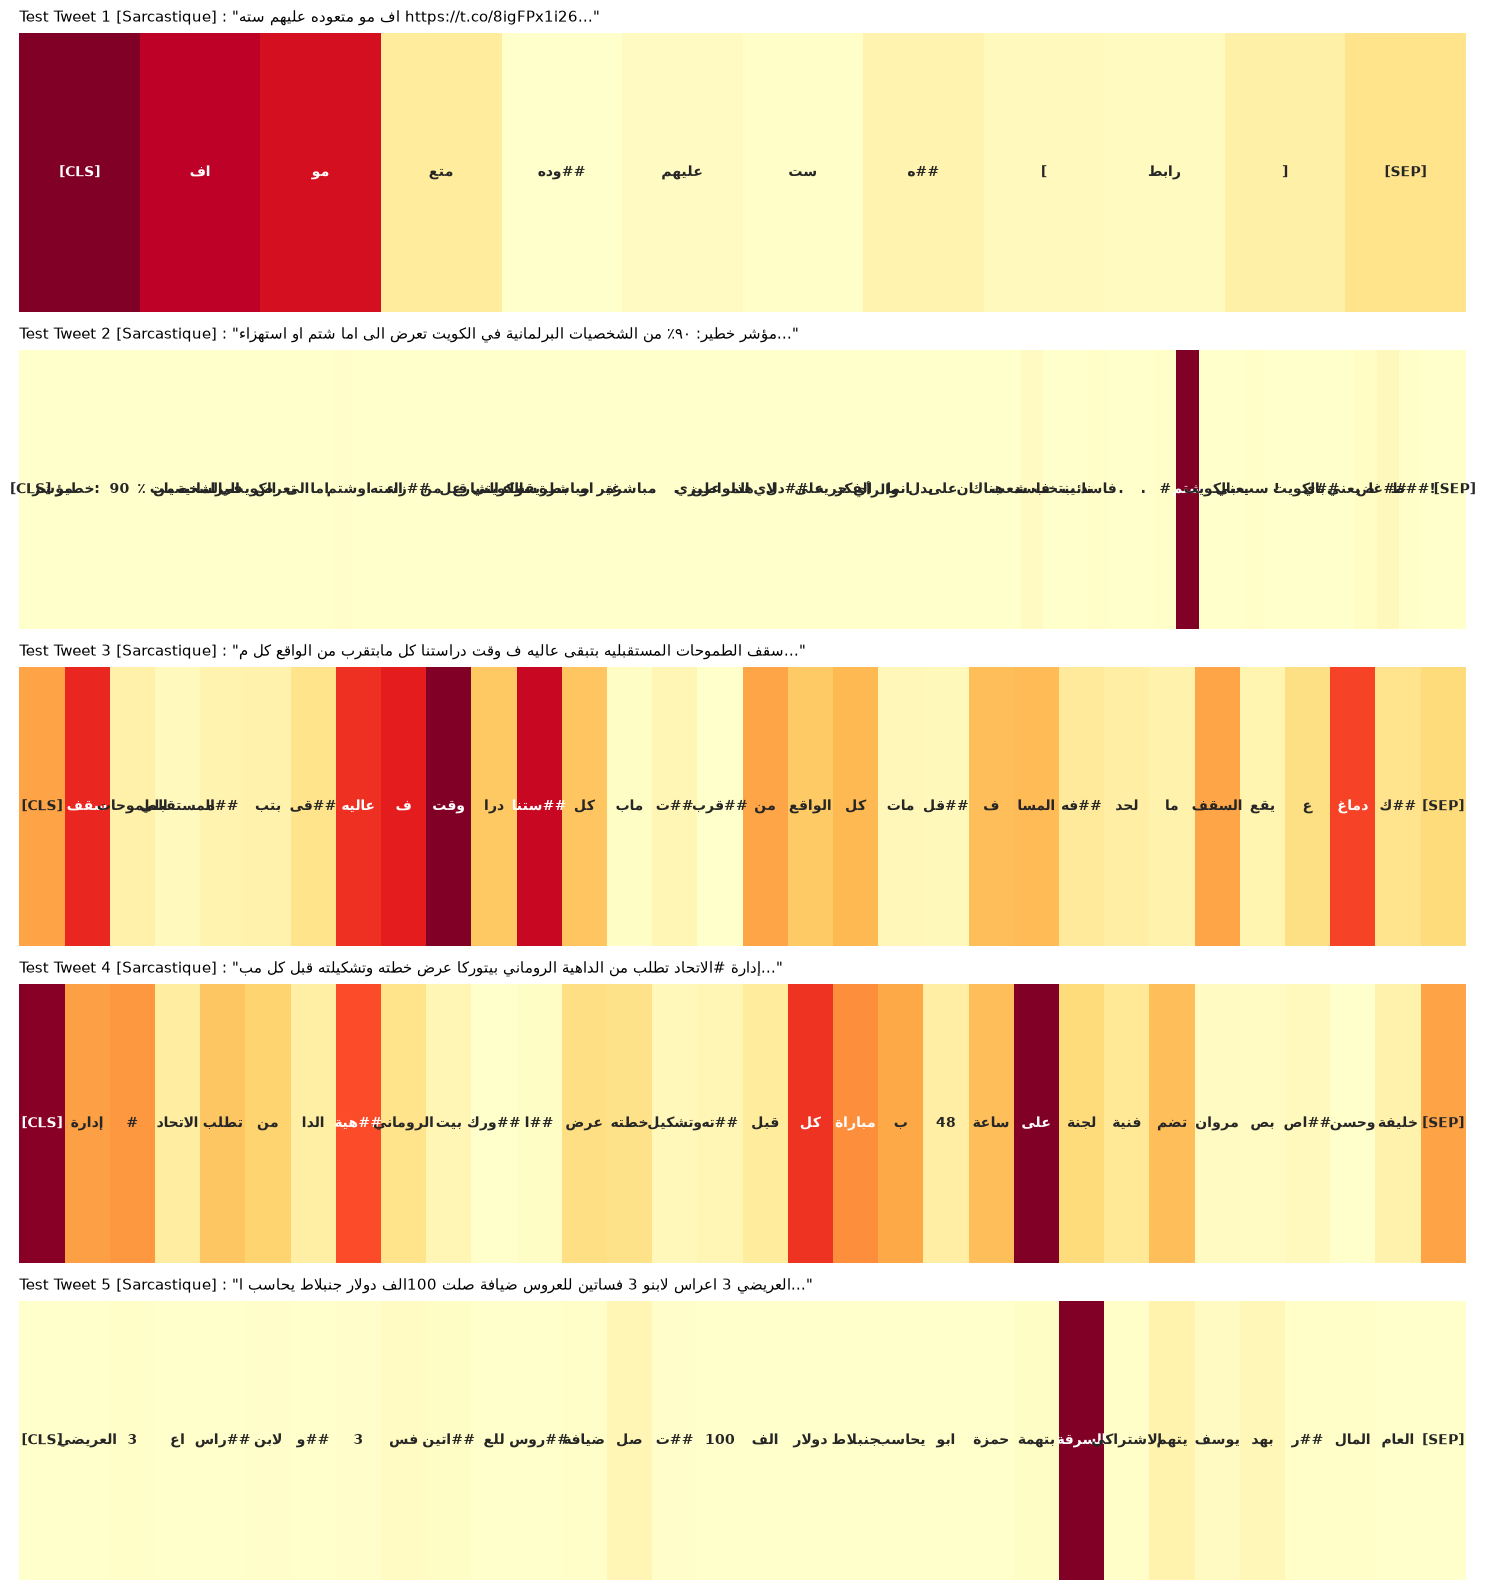

Figure sauvegardée sous 'attention_5_tweets_test.png' !


In [14]:
# Sélection de 5 tweets sarcastiques réels du TEST
sarcastic_test_idx = np.where(y_test == 1)[0][:5]

d2_head.eval()
fig, axes = plt.subplots(5, 1, figsize=(15, 16))
plt.subplots_adjust(hspace=0.8)

for plot_idx, idx in enumerate(sarcastic_test_idx):
    raw_tweet = test_df["tweet"].iloc[idx]
    prep_tweet = test_texts[idx]
    
    encoded = tokenizer(
        prep_tweet,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LEN
    ).to(DEVICE)
    
    with torch.no_grad():
        outputs = encoder(**encoded)
        _, attn_weights = d2_head(outputs.last_hidden_state, encoded["attention_mask"])
        
    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    weights = attn_weights[0].cpu().numpy()
    
    seq_len = encoded["attention_mask"][0].sum().item()
    tokens = tokens[:seq_len]
    weights = weights[:seq_len]
    weights = weights / weights.sum() # Normalisation pour l'affichage
    
    # Affichage en Heatmap
    ax = axes[plot_idx]
    sns.heatmap(
        weights.reshape(1, -1),
        annot=np.array(tokens).reshape(1, -1),
        fmt="",
        cmap="YlOrRd",
        cbar=False,
        ax=ax,
        annot_kws={"size": 10, "weight": "bold"}
    )
    ax.set_title(f"Test Tweet {plot_idx+1} [Sarcastique] : \"{raw_tweet[:75]}...\"", fontsize=11, loc="left", pad=8)
    ax.set_yticks([])
    ax.set_xticks([])

plt.tight_layout()
plt.savefig("attention_5_tweets_test.png", dpi=300, bbox_inches="tight")
plt.show()
print("Figure sauvegardée sous 'attention_5_tweets_test.png' !")
